# Практична робота № 4. Відкриті міські дані та індикатори сталості
## Варіант 4. Якість повітря в районах Львова, 2023 рік (PM2.5)

**Питання дослідження:** Який район Львова має найбільшу кількість днів із перевищенням середньодобової настанови ВООЗ для PM2.5 та в які місяці такі перевищення трапляються найчастіше?

**Дані:** набір data.gov.ua «Щогодинні концентрації та індекс якості атмосферного повітря для дрібнодисперсного пилу фракції 2.5 мікронів у районах населених пунктів України» (розпорядник – ГО «SaveDnipro», ліцензія CC BY).

**Конвеєр:** завантаження → очищення → оцінка якості даних → обчислення індикаторів → візуалізація → порівняння районів → висновки.

### Крок 1-2. Структура папки роботи й віртуальне середовище й завантаження даних

### Крок 3. Імпорт бібліотек і налаштування

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Шляхи відносно кореня репозиторію
# (ноутбук лежить у папці notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

YEARS = [2023]
CITY_NAME = "Львів"
REGION_NAME = "Львівська область"

# Нормативи для порівняння, мкг/м³
WHO_ANNUAL = 5       # ВООЗ 2021, середньорічна
WHO_DAILY = 15       # ВООЗ 2021, середньодобова
EU_ANNUAL_2030 = 10  # ЄС з 2030 р., середньорічна
EU_DAILY_2030 = 25   # ЄС з 2030 р., середньодобова

pd.set_option("display.max_columns", 20)
print("pandas", pd.__version__)
print("Файли в data/raw:",
      sorted(p.name for p in RAW.glob("*.csv")))

pandas 3.1.0
Файли в data/raw: ['saveecobot_aqi_cities.csv', 'saveecobot_cities_pm25_and_aqi_pm25_2023.csv', 'saveecobot_city_districts.csv', 'saveecobot_city_districts_pm25_and_aqi_pm25_2023.csv']


### Крок 4. Довідник районів Львова: ідентифікатори районів

Щогодинні файли містять не назву міста, а числовий ідентифікатор `city_id`. Назви лежать в окремому
довіднику. Це типова структура відкритих даних: **таблиця фактів** (виміри) + **довідник** (опис об'єктів).

In [3]:
districts = pd.read_csv(
    RAW / "saveecobot_city_districts.csv",
    encoding="utf-8"
)

lviv_districts = districts[
    (districts["city_name"] == "Львів")
    & (districts["region_name"] == "Львівська область")
]

lviv_districts[
    ["id", "district_name", "city_name", "region_name"]
]

,id,district_name,city_name,region_name
34,58,Залізничний район,Львів,Львівська область
35,59,Галицький район,Львів,Львівська область
36,60,Сихівський район,Львів,Львівська область
37,61,Франківський район,Львів,Львівська область
38,62,Личаківський район,Львів,Львівська область
39,63,Шевченківський район,Львів,Львівська область


### Крок 5. Завантаження щогодинних даних Львова

Файл містить щогодинні дані PM2.5 за районами населених пунктів України. Для подальшого аналізу відбираємо дані районів Львова за 2023 рік за їхніми district_id.

In [4]:
district_ids = lviv_districts["id"].tolist()

raw = pd.read_csv(
    RAW / "saveecobot_city_districts_pm25_and_aqi_pm25_2023.csv",
    encoding="utf-8",
    sep=",",
    usecols=["district_id", "pm25", "logged_at"],
    dtype={
        "district_id": "int32",
        "pm25": "float64",
        "logged_at": "string"
    }
)

raw = raw[raw["district_id"].isin(district_ids)].copy()

district_names = lviv_districts.set_index("id")["district_name"]
raw["district_name"] = raw["district_id"].map(district_names)

print("Усього рядків для районів Львова:", len(raw))
print("\nКількість рядків за районами:")
print(raw.groupby("district_name").size())

raw.info()
raw.head()

Усього рядків для районів Львова: 47595

Кількість рядків за районами:
district_name
Галицький район         8759
Залізничний район       8759
Личаківський район      8740
Сихівський район        8729
Франківський район      8613
Шевченківський район    3995
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 47595 entries, 114224 to 161818
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   district_id    47595 non-null  int32  
 1   pm25           47380 non-null  float64
 2   logged_at      47595 non-null  string 
 3   district_name  47595 non-null  str    
dtypes: float64(1), int32(1), str(1), string(1)
memory usage: 1.3 MB


,district_id,pm25,logged_at,district_name
114224,58,4.542,2023-01-01 00:00:00,Залізничний район
114225,58,5.954,2023-01-01 01:00:00,Залізничний район
114226,58,7.214,2023-01-01 02:00:00,Залізничний район
114227,58,6.290,2023-01-01 03:00:00,Залізничний район
114228,58,6.484,2023-01-01 04:00:00,Залізничний район


### Крок 6. Очищення даних

Перевіряємо: типи даних, пропуски, неможливі значення, дублікати, порядок записів.

In [5]:
df = raw.copy()

# 1. Перетворюємо дату й час
df["logged_at"] = pd.to_datetime(
    df["logged_at"],
    format="%Y-%m-%d %H:%M:%S"
)

# 2. Перевіряємо пропуски
print("Пропуски за стовпцями:")
print(df.isna().sum())

# 3. Перевіряємо неможливі значення PM2.5
bad = df[(df["pm25"] < 0) | (df["pm25"] > 1000)]
print("\nНеможливих значень:", len(bad))

# 4. Перевіряємо повні дублікати
print("Повних дублікатів рядків:", df.duplicated().sum())

# 5. Перевіряємо повтори однієї години в межах одного району
print(
    "Повторів години в межах району:",
    df.duplicated(subset=["district_id", "logged_at"]).sum()
)

Пропуски за стовпцями:
district_id        0
pm25             215
logged_at          0
district_name      0
dtype: int64

Неможливих значень: 0
Повних дублікатів рядків: 0
Повторів години в межах району: 0


In [6]:
df = (
    df.drop_duplicates(subset=["district_id", "logged_at"])
      .loc[lambda d: d["pm25"].between(0, 1000)]
      .sort_values(["district_id", "logged_at"])
      .set_index("logged_at")
)

print(len(raw), "→", len(df), "рядків після очищення")

print("\nРядків після очищення за районами:")
print(df.groupby("district_name").size())

print("\nОпис PM2.5:")
print(df["pm25"].describe().round(1))

47595 → 47380 рядків після очищення

Рядків після очищення за районами:
district_name
Галицький район         8758
Залізничний район       8758
Личаківський район      8719
Сихівський район        8719
Франківський район      8536
Шевченківський район    3890
dtype: int64

Опис PM2.5:
count    47380.0
mean        10.4
std          7.2
min          0.3
25%          5.4
50%          8.6
75%         13.7
max        189.1
Name: pm25, dtype: float64


**Пояснення** Під час перевірки якості даних було виявлено 215 пропущених значень у стовпці PM2.5. Пропусків у назвах та ідентифікаторах районів і даті вимірювання не виявлено. Також не було знайдено неможливих значень PM2.5 поза заданим допустимим діапазоном 0–1000 мкг/м³, повних дублікатів рядків або повторних вимірювань для одного району в одну й ту саму годину.

Рядки з відсутнім значенням PM2.5 було виключено з подальших розрахунків, оскільки заміна таких пропусків нульовими значеннями штучно знизила б середні концентрації та спотворила б результати аналізу. Після очищення кількість записів зменшилася з 47 595 до 47 380. Записи також було впорядковано за районом і часом вимірювання, що необхідно для подальшого аналізу часових рядів і розрахунку добових та місячних показників.

### Крок 7.Оцінка якості даних: повнота і пропуски

**Повнота (completeness)** — частка годин, для яких є вимір. Індикатор, обчислений на неповних даних,
може бути зміщеним: якщо пропущено переважно зимові місяці, середньорічне значення буде заниженим.

In [7]:
full_hours = pd.date_range(
    "2023-01-01 00:00:00",
    "2023-12-31 23:00:00",
    freq="h"
)

completeness_parts = []
annual_values = {}

for (district_id, district_name), group in df.groupby(
    ["district_id", "district_name"]
):
    series = group["pm25"].reindex(full_hours)

    monthly = (series.notna().resample("MS").mean() * 100).round(1)

    part = monthly.to_frame("повнота_%")
    part["district_name"] = district_name
    part["місяць"] = part.index.month

    completeness_parts.append(part)

    annual_values[district_name] = round(series.notna().mean() * 100, 1)

completeness = pd.concat(completeness_parts)

completeness_table = completeness.pivot(
    index="місяць",
    columns="district_name",
    values="повнота_%"
)

annual_completeness = pd.Series(
    annual_values,
    name="повнота_%"
).sort_values(ascending=False)

display(completeness_table)
display(annual_completeness)

district_name,Галицький район,Залізничний район,Личаківський район,Сихівський район,Франківський район,Шевченківський район
місяць,,,,,,
1,100.0,100.0,100.0,99.2,83.6,51.3
2,100.0,100.0,100.0,100.0,96.4,89.0
3,99.7,99.7,97.8,99.7,99.7,99.7
4,100.0,100.0,100.0,100.0,100.0,100.0
5,100.0,100.0,100.0,100.0,100.0,100.0
6,100.0,100.0,100.0,100.0,100.0,48.3
7,100.0,100.0,100.0,99.5,100.0,45.0
8,100.0,100.0,100.0,100.0,100.0,0.0
9,100.0,100.0,99.4,96.9,100.0,2.9


Залізничний район       100.0
Галицький район         100.0
Сихівський район         99.5
Личаківський район       99.5
Франківський район       97.4
Шевченківський район     44.4
Name: повнота_%, dtype: float64

In [8]:
all_gaps = []

for district_name, group in df.groupby("district_name"):

    series = group["pm25"].reindex(full_hours)
    missing = series.isna()

    gap_id = (missing != missing.shift()).cumsum()

    gaps = (
        missing[missing]
        .groupby(gap_id[missing])
        .agg(
            початок=lambda s: s.index.min(),
            тривалість_год="size"
        )
        .sort_values("тривалість_год", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )

    gaps["district_name"] = district_name
    all_gaps.append(gaps)

gaps_table = pd.concat(all_gaps)

gaps_table.sort_values(
    "тривалість_год",
    ascending=False
).head(15)

,початок,тривалість_год,district_name
0,2023-09-12 11:00:00,2653,Шевченківський район
1,2023-07-27 19:00:00,1099,Шевченківський район
2,2023-06-15 12:00:00,680,Шевченківський район
3,2023-01-05 13:00:00,147,Шевченківський район
4,2023-01-11 18:00:00,28,Шевченківський район
0,2023-09-04 18:00:00,22,Сихівський район
0,2023-12-21 00:00:00,19,Франківський район
1,2023-12-02 00:00:00,19,Франківський район
2,2023-12-02 20:00:00,16,Франківський район
3,2023-12-28 20:00:00,8,Франківський район


**Оцінка**Оцінка повноти показала, що для більшості районів Львова дані за 2023 рік майже повні. Річна повнота становила 100,0% для Залізничного та Галицького районів, 99,5% для Сихівського та Личаківського районів і 97,4% для Франківського району. Натомість для Шевченківського району повнота становила лише 44,4%, тому його дані було виключено з подальшого порівняння районів як недостатньо репрезентативні.

Пропуски можуть бути пов’язані з тимчасовими збоями сенсорів, відсутністю електроживлення або зв’язку, припиненням передачі даних окремими станціями чи зміною кількості активних сенсорів. Особливо великі неперервні пропуски у Шевченківському районі свідчать про те, що проблема не обмежувалася випадковою відсутністю окремих годин. Використання такого неповного ряду могло б спотворити середньорічні показники та кількість днів із перевищеннями.

### Крок 8. Середньодобові значення

За поширеним правилом (зокрема в практиці ЄС) середньодобове значення вважається дійсним,
якщо є щонайменше **18 із 24** годинних вимірів (75 %).

In [9]:
daily_parts = []

for (district_id, district_name), group in df.groupby(
    ["district_id", "district_name"]
):
    series = group["pm25"].reindex(full_hours)

    district_daily = series.resample("D").agg(["mean", "count"])

    district_daily["valid"] = district_daily["count"] >= 18

    # Недійсні доби не враховуємо в подальших розрахунках
    district_daily.loc[
        ~district_daily["valid"], "mean"
    ] = float("nan")

    district_daily["district_id"] = district_id
    district_daily["district_name"] = district_name

    daily_parts.append(district_daily)

daily = pd.concat(daily_parts)

print("Недійсних діб за районами:")
print(
    daily.groupby("district_name")["valid"]
         .apply(lambda s: (~s).sum())
)

print("\nДійсних діб за районами:")
print(
    daily.groupby("district_name")["valid"].sum()
)

daily.head()

Недійсних діб за районами:
district_name
Галицький район           0
Залізничний район         0
Личаківський район        3
Сихівський район          2
Франківський район        8
Шевченківський район    214
Name: valid, dtype: int64

Дійсних діб за районами:
district_name
Галицький район         365
Залізничний район       365
Личаківський район      362
Сихівський район        363
Франківський район      357
Шевченківський район    151
Name: valid, dtype: int64


,mean,count,valid,district_id,district_name
2023-01-01,5.590167,24,True,58,Залізничний район
2023-01-02,7.907583,24,True,58,Залізничний район
2023-01-03,7.852292,24,True,58,Залізничний район
2023-01-04,10.296313,24,True,58,Залізничний район
2023-01-05,2.558787,24,True,58,Залізничний район


### Крок 9. Обчислення індикаторів

| Індикатор | Методика |
|---|---|
| Середньорічна концентрація PM2.5 | середнє дійсних середньодобових значень за рік (ISO 37120, ЦСР 11.6.2) |
| Повнота даних | частка дійсних діб у році; річне значення вважаємо надійним при ≥ 90 % |
| Дні з перевищенням настанови ВООЗ | кількість діб із середньодобовою концентрацією > 15 мкг/м³ (ВООЗ допускає 3–4 на рік) |
| Дні з перевищенням граничної величини ЄС-2030 | кількість діб > 25 мкг/м³ (допускається до 18 на рік) |

In [10]:
def who_level(x: float) -> str:
    levels = [
        (5, "настанова ВООЗ"),
        (10, "IT-4"),
        (15, "IT-3"),
        (25, "IT-2"),
        (35, "IT-1")
    ]

    for limit, name in levels:
        if x <= limit:
            return name

    return "гірше IT-1"


ind = daily.groupby("district_name").agg(
    середньорічна_pm25=("mean", "mean"),
    дійсних_діб=("valid", "sum"),
    діб_у_році=("valid", "size"),
    діб_понад_15=("mean", lambda s: (s > WHO_DAILY).sum()),
    діб_понад_25=("mean", lambda s: (s > EU_DAILY_2030).sum())
)

ind["повнота_%"] = (
    ind["дійсних_діб"] / ind["діб_у_році"] * 100
).round(1)

ind["надійно"] = ind["повнота_%"] >= 90

ind["рівень_ВООЗ"] = (
    ind["середньорічна_pm25"].apply(who_level)
)

ind["у_разів_вище_ВООЗ"] = (
    ind["середньорічна_pm25"] / WHO_ANNUAL
).round(1)

ind["середньорічна_pm25"] = (
    ind["середньорічна_pm25"].round(1)
)

ind

,середньорічна_pm25,дійсних_діб,діб_у_році,діб_понад_15,діб_понад_25,повнота_%,надійно,рівень_ВООЗ,у_разів_вище_ВООЗ
district_name,,,,,,,,,
Галицький район,13.7,365,365,131,16,100.0,True,IT-3,2.7
Залізничний район,7.4,365,365,18,1,100.0,True,IT-4,1.5
Личаківський район,7.3,362,365,26,2,99.2,True,IT-4,1.5
Сихівський район,11.7,363,365,87,5,99.5,True,IT-3,2.3
Франківський район,12.6,357,365,102,18,97.8,True,IT-3,2.5
Шевченківський район,9.5,151,365,23,3,41.4,False,IT-4,1.9


### Ручна перевірка: Франківський район, 2023 рік

Для Франківського району отримано 357 дійсних діб із 365.

Повнота даних:
357 / 365 × 100 % = 97,8 %.

Оскільки повнота перевищує 90 %, річне значення вважається надійним.

Середньорічна концентрація PM2.5 становить 12,6 мкг/м³. Оскільки 10 < 12,6 ≤ 15, показник відповідає рівню ВООЗ IT-3.

Кратність перевищення настанови ВООЗ:
12,6 / 5 = 2,52 ≈ 2,5 раза.

За 2023 рік у Франківському районі зафіксовано 102 доби з концентрацією PM2.5 понад 15 мкг/м³ та 18 діб понад 25 мкг/м³.

### Крок 10. Візуалізація

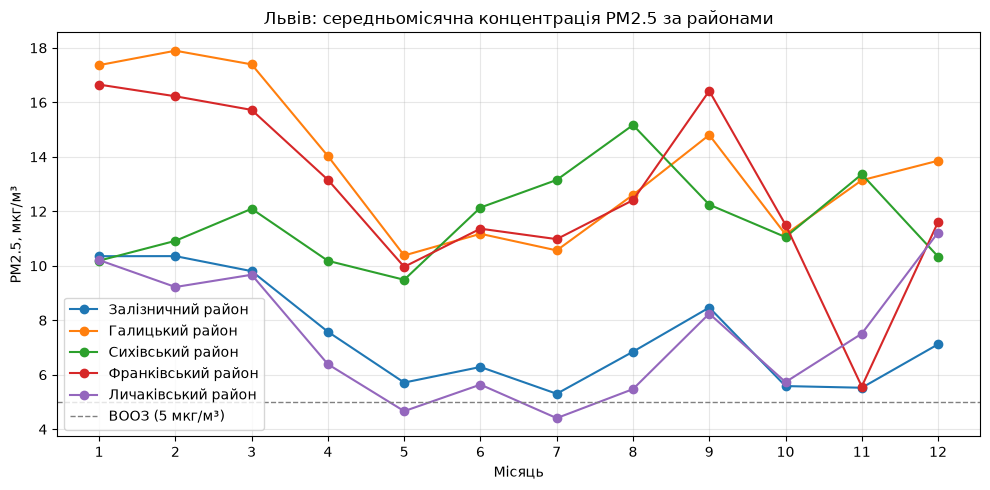

In [11]:
TARGET_DISTRICTS = [
    "Залізничний район",
    "Галицький район",
    "Сихівський район",
    "Франківський район",
    "Личаківський район"
]

monthly_parts = []

for district_name, group in daily[
    daily["district_name"].isin(TARGET_DISTRICTS)
].groupby("district_name"):

    monthly = group["mean"].resample("MS").mean()

    part = monthly.to_frame("pm25")
    part["district_name"] = district_name
    part["місяць"] = part.index.month

    monthly_parts.append(part)

monthly_districts = pd.concat(monthly_parts)

fig, ax = plt.subplots(figsize=(10, 5))

for district_name in TARGET_DISTRICTS:
    m = monthly_districts[
        monthly_districts["district_name"] == district_name
    ]

    ax.plot(
        m["місяць"],
        m["pm25"],
        marker="o",
        label=district_name
    )

ax.axhline(
    WHO_ANNUAL,
    linestyle="--",
    color="gray",
    linewidth=1,
    label="ВООЗ (5 мкг/м³)"
)

ax.set_xticks(range(1, 13))
ax.set_xlabel("Місяць")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title("Львів: середньомісячна концентрація PM2.5 за районами")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES / "monthly_pm25_districts.png", dpi=150)

plt.show()

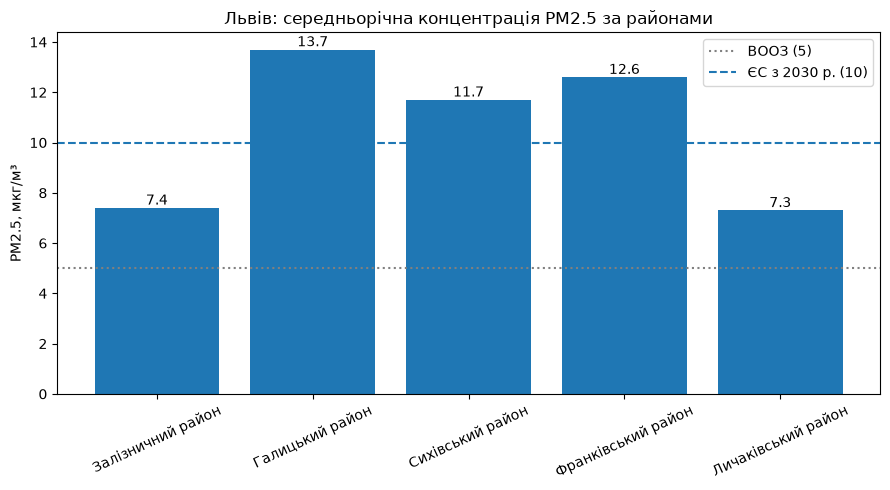

In [12]:
annual_plot = ind.loc[
    TARGET_DISTRICTS,
    "середньорічна_pm25"
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    annual_plot.index,
    annual_plot.values
)

ax.bar_label(bars, fmt="%.1f")

ax.axhline(
    WHO_ANNUAL,
    linestyle=":",
    color="gray",
    label="ВООЗ (5)"
)

ax.axhline(
    EU_ANNUAL_2030,
    linestyle="--",
    label="ЄС з 2030 р. (10)"
)

ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title("Львів: середньорічна концентрація PM2.5 за районами")
ax.tick_params(axis="x", rotation=25)
ax.legend()

fig.tight_layout()
fig.savefig(FIGURES / "annual_pm25_districts.png", dpi=150)

plt.show()

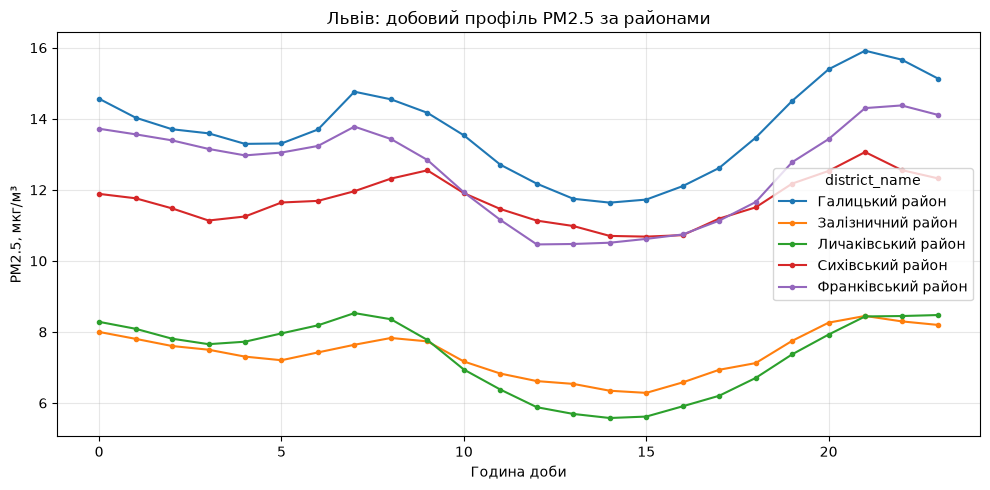

In [13]:
profile = (
    df[df["district_name"].isin(TARGET_DISTRICTS)]
    .assign(hour=lambda x: x.index.hour)
    .groupby(["district_name", "hour"])["pm25"]
    .mean()
    .unstack(0)
)

ax = profile.plot(
    figsize=(10, 5),
    marker="."
)

ax.set_xlabel("Година доби")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title("Львів: добовий профіль PM2.5 за районами")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES / "diurnal_profile_districts.png", dpi=150)
plt.show()

### Крок 10.1. Творча частина: порівняння районів Львова

### Гіпотеза
Припускаємо, що у всіх районах Львова найбільша кількість днів із перевищенням середньодобової настанови ВООЗ для PM2.5 (> 15 мкг/м³) припадає на опалювальний період (жовтень–квітень).

In [14]:
creative_daily = daily[
    daily["district_name"].isin(TARGET_DISTRICTS)
].copy()

creative_daily["місяць"] = creative_daily.index.month

creative_daily["перевищення_ВООЗ"] = (
    creative_daily["mean"] > WHO_DAILY
)

monthly_exceed = (
    creative_daily
    .groupby(["місяць", "district_name"])["перевищення_ВООЗ"]
    .sum()
    .unstack(fill_value=0)
)

total_exceed = (
    creative_daily
    .groupby("district_name")["перевищення_ВООЗ"]
    .sum()
    .sort_values(ascending=False)
)

print("Кількість днів із перевищенням ВООЗ за 2023 рік:")
display(total_exceed)

print("\nПеревищення за місяцями:")
display(monthly_exceed)

Кількість днів із перевищенням ВООЗ за 2023 рік:


district_name
Галицький район       131
Франківський район    102
Сихівський район       87
Личаківський район     26
Залізничний район      18
Name: перевищення_ВООЗ, dtype: int64


Перевищення за місяцями:


district_name,Галицький район,Залізничний район,Личаківський район,Сихівський район,Франківський район
місяць,,,,,
1,26,2,2,2,17
2,14,7,5,7,13
3,16,6,5,8,12
4,12,1,1,2,10
5,3,0,1,3,3
6,4,0,0,9,8
7,1,0,0,12,2
8,11,0,0,17,8
9,15,1,2,7,14


In [15]:
# Нова перевірювана гіпотеза:
# У всіх районах Львова найбільше перевищень PM2.5
# припадає на опалювальний період.

heating_months = {1, 2, 3, 4, 10, 11, 12}

month_names = {
    1: "Січень",
    2: "Лютий",
    3: "Березень",
    4: "Квітень",
    5: "Травень",
    6: "Червень",
    7: "Липень",
    8: "Серпень",
    9: "Вересень",
    10: "Жовтень",
    11: "Листопад",
    12: "Грудень"
}

results = []

for district in monthly_exceed.columns:
    max_count = int(monthly_exceed[district].max())

    max_months = [
        int(m)
        for m in monthly_exceed.index[
            monthly_exceed[district] == max_count
        ].tolist()
    ]

    heating = all(m in heating_months for m in max_months)

    results.append({
        "Район": district,
        "Місяць(і) максимуму": ", ".join(month_names[m] for m in max_months),
        "Кількість днів": max_count,
        "Опалювальний період": "Так" if heating else "Ні"
    })

hypothesis_result = pd.DataFrame(results)

display(hypothesis_result)

confirmed = (hypothesis_result["Опалювальний період"] == "Так").all()

print("\nГіпотеза:")
print("У всіх районах Львова найбільше перевищень PM2.5 припадає на опалювальний період.")

if confirmed:
    print("\nВисновок: гіпотезу підтверджено.")
else:
    print("\nВисновок: гіпотезу підтверджено не повністю.")

hypothesis_result.to_csv(
    PROCESSED / "lviv_districts_max_exceedance_months_2023.csv",
    index=False,
    encoding="utf-8-sig"
)

,Район,Місяць(і) максимуму,Кількість днів,Опалювальний період
0,Галицький район,Січень,26,Так
1,Залізничний район,Лютий,7,Так
2,Личаківський район,Грудень,10,Так
3,Сихівський район,Серпень,17,Ні
4,Франківський район,Січень,17,Так



Гіпотеза:
У всіх районах Львова найбільше перевищень PM2.5 припадає на опалювальний період.

Висновок: гіпотезу підтверджено не повністю.


**Результат перевірки гіпотези.** Гіпотезу підтверджено частково. У Галицькому районі найбільша кількість днів із перевищенням припала на січень — 26 днів, у Залізничному — на лютий — 7 днів, у Личаківському — на грудень — 10 днів, у Франківському — на січень — 17 днів. У цих чотирьох районах максимуми припадають на опалювальний період. Водночас у Сихівському районі найбільше перевищень зафіксовано у серпні — 17 днів, тобто поза опалювальним періодом. Отже, припущення про те, що в усіх районах найбільше перевищень припадає на опалювальний період, повністю не підтвердилося.

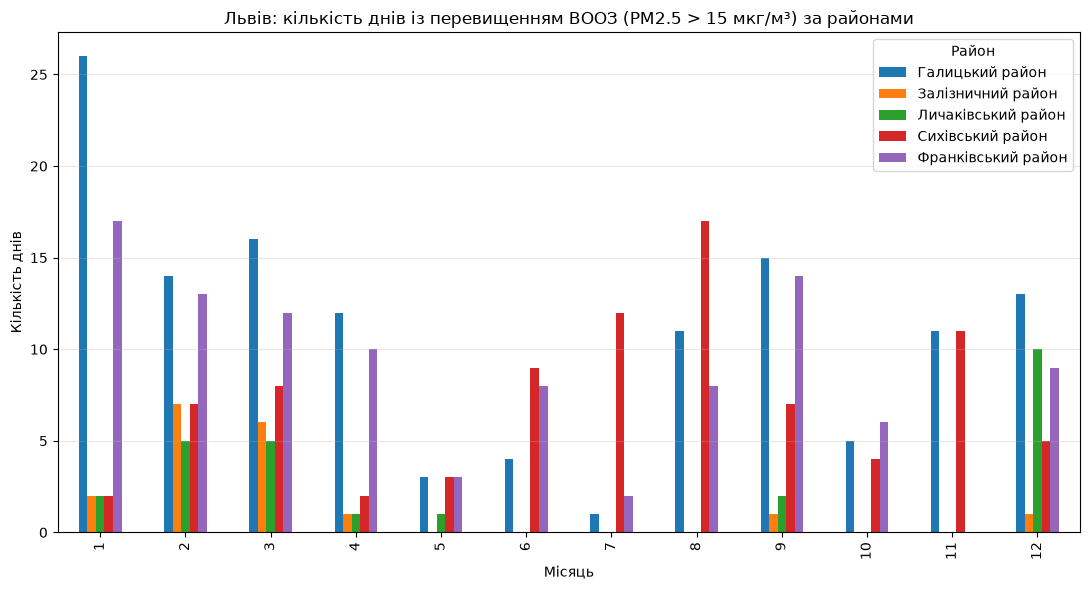

In [16]:
ax = monthly_exceed.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_xlabel("Місяць")
ax.set_ylabel("Кількість днів")
ax.set_title(
    "Львів: кількість днів із перевищенням ВООЗ "
    "(PM2.5 > 15 мкг/м³) за районами"
)

ax.legend(title="Район")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES / "who_exceedances_by_district_month.png",
    dpi=150
)
plt.show()

### Результат творчої частини

Найбільшу кількість днів із перевищенням середньодобової настанови ВООЗ для PM2.5 (> 15 мкг/м³) у 2023 році зафіксовано в Галицькому районі — 131 добу. На другому місці Франківський район — 102 доби, далі Сихівський — 87, Личаківський — 26 та Залізничний — 18 діб.

У Галицькому районі найбільше перевищень спостерігалося в січні — 26 діб. Загалом серед п'яти досліджуваних районів найбільша кількість перевищень також припала на січень — 49 діб.

Отже, висунута гіпотеза підтвердилася: кількість днів із підвищеною концентрацією PM2.5 суттєво відрізняється між районами Львова та має виражені відмінності за місяцями.

### Крок 11. Експорт результатів

Очищені середньодобові дані знадобляться в Практичній роботі № 5 (дашборд) і № 7 (геоаналіз).

In [17]:
out = daily.rename(
    columns={
        "mean": "pm25_mean",
        "count": "hours"
    }
)

out.to_csv(
    PROCESSED / "lviv_districts_pm25_daily_2023.csv"
)

ind.to_csv(
    PROCESSED / "lviv_districts_pm25_indicators_2023.csv"
)

print(
    "Збережено:",
    sorted(p.name for p in PROCESSED.glob("*.csv"))
)

Збережено: ['lviv_districts_max_exceedance_months_2023.csv', 'lviv_districts_pm25_daily_2023.csv', 'lviv_districts_pm25_indicators_2023.csv']


### Крок 12. Висновки й обмеження

Висновки записуються у звіт (README.md) з опорою на числа з таблиці індикаторів і графіки.
Обов'язково вкажіть обмеження даних: недорогі сенсори громадян, а не референтні станції; змінна кількість
сенсорів у місті; позначки часу в місцевому часі з переходом на літній час; можливі пропуски
через відключення електроенергії.

### Крок 14 (додатково). Аналіз чутливості індикатора

Перевіримо, як змінюються середньорічна концентрація PM2.5 та кількість дійсних діб, якщо мінімальну кількість годинних вимірювань для дійсної доби змінити з 18 до 12 або 22 годин.

In [18]:
threshold_results = []

for threshold in [12, 18, 22]:

    for (district_id, district_name), group in df[
        df["district_name"].isin(TARGET_DISTRICTS)
    ].groupby(["district_id", "district_name"]):

        series = group["pm25"].reindex(full_hours)

        temp_daily = series.resample("D").agg(["mean", "count"])

        temp_daily["valid"] = temp_daily["count"] >= threshold

        annual_mean = temp_daily.loc[
            temp_daily["valid"], "mean"
        ].mean()

        valid_days = temp_daily["valid"].sum()

        threshold_results.append({
            "district_name": district_name,
            "поріг_годин": threshold,
            "дійсних_діб": valid_days,
            "середньорічна_pm25": annual_mean
        })

sensitivity = pd.DataFrame(threshold_results)

result_table = sensitivity.pivot(
    index="district_name",
    columns="поріг_годин",
    values=["дійсних_діб", "середньорічна_pm25"]
).round(1)

result_table

дійсних_діб               середньорічна_pm25            
поріг_годин                 12     18     22                 12    18    22
district_name                                                              
Галицький район          365.0  365.0  365.0               13.7  13.7  13.7
Залізничний район        365.0  365.0  365.0                7.4   7.4   7.4
Личаківський район       365.0  362.0  360.0                7.3   7.3   7.4
Сихівський район         364.0  363.0  360.0               11.7  11.7  11.7
Франківський район       363.0  357.0  331.0               12.6  12.6  12.3

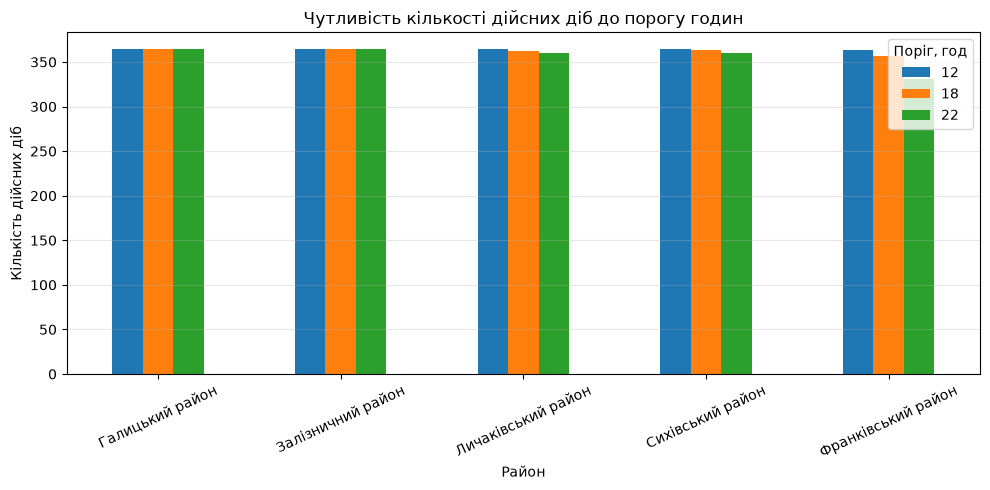

In [19]:
valid_days_plot = sensitivity.pivot(
    index="district_name",
    columns="поріг_годин",
    values="дійсних_діб"
)

ax = valid_days_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_xlabel("Район")
ax.set_ylabel("Кількість дійсних діб")
ax.set_title("Чутливість кількості дійсних діб до порогу годин")
ax.legend(title="Поріг, год")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES / "sensitivity_valid_days.png",
    dpi=150
)
plt.show()

### Висновок

Зміна мінімального порогу з 18 до 12 годин майже не впливає на середньорічну концентрацію PM2.5. При підвищенні порогу до 22 годин кількість дійсних діб зменшується, найбільше у Франківському районі — з 357 до 331 доби. При цьому середньорічна концентрація змінюється незначно: з 12,6 до 12,3 мкг/м³. Отже, отримані річні показники загалом є стійкими до зміни критерію дійсної доби. Обмеження дослідження пов’язані з якістю та повнотою даних громадського моніторингу саме для Львова. Шевченківський район не включався до порівняльного аналізу через низьку річну повноту даних — 44,4%. Крім того, кількість і розташування сенсорів у різних районах Львова можуть бути нерівномірними, а технічні збої та перерви у передачі даних можуть впливати на отримані середні значення. Тому результати характеризують доступні дані сенсорів за 2023 рік і не повинні трактуватися як повна характеристика якості повітря на всій території кожного району.